In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
%matplotlib inline

pd.set_option("display.max_columns", None)

In [2]:
FILE_PATH =  "C:\\Users\\mrity\\Downloads\\Inventory_SupplyChain_Dataset (1).csv"
df = pd.read_csv(FILE_PATH)

print("Shape:", df.shape)
df.head()

Shape: (1200, 15)


,Date,Region,Category,Supplier,Warehouse,Order Status,Units Sold,Inventory Level,Transportation Cost,Order Accuracy,Lead Time (Days),Backorder,Cost of Goods Sold (COGS),Average Inventory,Warehouse Capacity
0,14-01-2020,North,Accessories,Supplier A,Warehouse 1,Fulfilled,302,2124,1103.838324,True,9,False,37820.05240,2048.0,5037
1,15-11-2020,East,Furniture,Supplier D,Warehouse 2,Fulfilled,741,1972,13163.007660,True,11,False,54396.17369,1213.0,9216
2,16-04-2020,East,Furniture,Supplier C,Warehouse 2,Fulfilled,940,454,9872.294126,True,17,False,24217.45462,1160.5,7699
3,17-04-2020,South,Accessories,Supplier D,Warehouse 2,Canceled,589,1867,4547.589932,True,3,False,38919.08005,3364.5,9271
4,18-04-2020,North,Accessories,Supplier C,Warehouse 2,Fulfilled,964,4862,11994.042310,True,21,False,59204.50683,3063.0,5828


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       1200 non-null   object 
 1   Region                     1200 non-null   object 
 2   Category                   1200 non-null   object 
 3   Supplier                   1200 non-null   object 
 4   Warehouse                  1200 non-null   object 
 5   Order Status               1200 non-null   object 
 6   Units Sold                 1200 non-null   int64  
 7   Inventory Level            1200 non-null   int64  
 8   Transportation Cost        1200 non-null   float64
 9   Order Accuracy             1200 non-null   bool   
 10  Lead Time (Days)           1200 non-null   int64  
 11  Backorder                  1200 non-null   bool   
 12  Cost of Goods Sold (COGS)  1200 non-null   float64
 13  Average Inventory          1200 non-null   float

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
Date                         0
Region                       0
Category                     0
Supplier                     0
Warehouse                    0
Order Status                 0
Units Sold                   0
Inventory Level              0
Transportation Cost          0
Order Accuracy               0
Lead Time (Days)             0
Backorder                    0
Cost of Goods Sold (COGS)    0
Average Inventory            0
Warehouse Capacity           0
dtype: int64

Duplicate rows: 0


In [5]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^\w\s]", "", regex=True)
    .str.replace(r"\s+", "_", regex=True)
)
print(list(df.columns))

['date', 'region', 'category', 'supplier', 'warehouse', 'order_status', 'units_sold', 'inventory_level', 'transportation_cost', 'order_accuracy', 'lead_time_days', 'backorder', 'cost_of_goods_sold_cogs', 'average_inventory', 'warehouse_capacity']


In [6]:
# 6. Parse date column (format DD-MM-YYYY)
df["date"] = pd.to_datetime(df["date"], format="%d-%m-%Y", errors="coerce")
df["date"].head()

0   2020-01-14
1   2020-11-15
2   2020-04-16
3   2020-04-17
4   2020-04-18
Name: date, dtype: datetime64[ns]

In [7]:
before = df.shape[0]
df = df.drop_duplicates()
print(f"Dropped {before - df.shape[0]} duplicate rows")

Dropped 0 duplicate rows


In [8]:
num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=["object"]).columns

for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


In [9]:
bool_cols = ["order_accuracy", "backorder"]
for col in bool_cols:
    if col in df.columns:
        df[col] = df[col].astype(bool)

for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()

df.dtypes

date                       datetime64[ns]
region                             object
category                           object
supplier                           object
warehouse                          object
order_status                       object
units_sold                          int64
inventory_level                     int64
transportation_cost               float64
order_accuracy                       bool
lead_time_days                      int64
backorder                            bool
cost_of_goods_sold_cogs           float64
average_inventory                 float64
warehouse_capacity                  int64
dtype: object

In [10]:
non_negative_cols = [
    "units_sold", "inventory_level", "transportation_cost",
    "lead_time_days", "cost_of_goods_sold_cogs",
    "average_inventory", "warehouse_capacity"
]
for col in non_negative_cols:
    if col in df.columns:
        invalid = (df[col] < 0).sum()
        if invalid > 0:
            print(f"Found {invalid} negative values in {col} -> clipping to 0")
            df[col] = df[col].clip(lower=0)

In [11]:
def flag_outliers_iqr(series, factor=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - factor * iqr, q3 + factor * iqr
    return (series < lower) | (series > upper)

outlier_summary = {}
for col in ["units_sold", "inventory_level", "transportation_cost",
            "lead_time_days", "cost_of_goods_sold_cogs"]:
    if col in df.columns:
        mask = flag_outliers_iqr(df[col])
        outlier_summary[col] = mask.sum()

pd.Series(outlier_summary, name="outlier_count")

units_sold                 0
inventory_level            0
transportation_cost        0
lead_time_days             0
cost_of_goods_sold_cogs    6
Name: outlier_count, dtype: int64

In [13]:
# Feature Engineeering
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()
df["weekday"] = df["date"].dt.day_name()

df["inventory_turnover"] = df["cost_of_goods_sold_cogs"] / df["average_inventory"].replace(0, np.nan)
df["capacity_utilization_pct"] = (df["inventory_level"] / df["warehouse_capacity"]) * 100

df.head()

,date,region,category,supplier,warehouse,order_status,units_sold,inventory_level,transportation_cost,order_accuracy,lead_time_days,backorder,cost_of_goods_sold_cogs,average_inventory,warehouse_capacity,year,month,month_name,weekday,inventory_turnover,capacity_utilization_pct
0,2020-01-14,North,Accessories,Supplier A,Warehouse 1,Fulfilled,302,2124,1103.838324,True,9,False,37820.05240,2048.0,5037,2020,1,January,Tuesday,18.466822,42.167957
1,2020-11-15,East,Furniture,Supplier D,Warehouse 2,Fulfilled,741,1972,13163.007660,True,11,False,54396.17369,1213.0,9216,2020,11,November,Sunday,44.844331,21.397569
2,2020-04-16,East,Furniture,Supplier C,Warehouse 2,Fulfilled,940,454,9872.294126,True,17,False,24217.45462,1160.5,7699,2020,4,April,Thursday,20.868121,5.896870
3,2020-04-17,South,Accessories,Supplier D,Warehouse 2,Canceled,589,1867,4547.589932,True,3,False,38919.08005,3364.5,9271,2020,4,April,Friday,11.567567,20.138065
4,2020-04-18,North,Accessories,Supplier C,Warehouse 2,Fulfilled,964,4862,11994.042310,True,21,False,59204.50683,3063.0,5828,2020,4,April,Saturday,19.328928,83.424846


In [14]:
# 13. Save cleaned dataset
df.to_csv("cleaned_inventory_supplychain.csv", index=False)
print("Saved -> cleaned_inventory_supplychain.csv")
print("Cleaned shape:", df.shape)

Saved -> cleaned_inventory_supplychain.csv
Cleaned shape: (1200, 21)


In [15]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,1200,2023-03-26 23:19:12,2020-01-14 00:00:00,2022-07-14 18:00:00,2023-05-11 12:00:00,2024-03-06 06:00:00,2024-12-31 00:00:00,NaN
units_sold,1200.0,533.8925,50.0,298.0,529.0,777.0,999.0,275.469524
inventory_level,1200.0,2530.473333,101.0,1261.75,2623.5,3726.25,4999.0,1416.945265
transportation_cost,1200.0,7723.518494,509.098991,4145.88205,7759.647979,11154.018832,14997.81405,4202.727652
lead_time_days,1200.0,15.739167,1.0,8.0,16.0,23.0,29.0,8.442187
cost_of_goods_sold_cogs,1200.0,59370.480017,1415.613541,22982.367025,47773.37675,88006.544317,190841.4954,44542.532052
average_inventory,1200.0,2529.588333,235.0,1843.0,2496.5,3240.125,4863.5,1000.512796
warehouse_capacity,1200.0,7425.831667,5002.0,6116.5,7427.0,8662.25,9995.0,1460.827133
year,1200.0,2022.74,2020.0,2022.0,2023.0,2024.0,2024.0,1.151161
month,1200.0,6.4475,1.0,4.0,6.0,9.0,12.0,3.325878


In [16]:
# 15. Categorical value counts
for col in ["region", "category", "supplier", "warehouse", "order_status"]:
    if col in df.columns:
        print(f"\n{col}:")
        print(df[col].value_counts())


region:
region
North    317
West     317
East     284
South    282
Name: count, dtype: int64

category:
category
Electronics    314
Clothing       311
Furniture      306
Accessories    269
Name: count, dtype: int64

supplier:
supplier
Supplier A    312
Supplier B    310
Supplier D    303
Supplier C    275
Name: count, dtype: int64

warehouse:
warehouse
Warehouse 1    403
Warehouse 3    403
Warehouse 2    394
Name: count, dtype: int64

order_status:
order_status
Fulfilled    838
Pending      248
Canceled     114
Name: count, dtype: int64


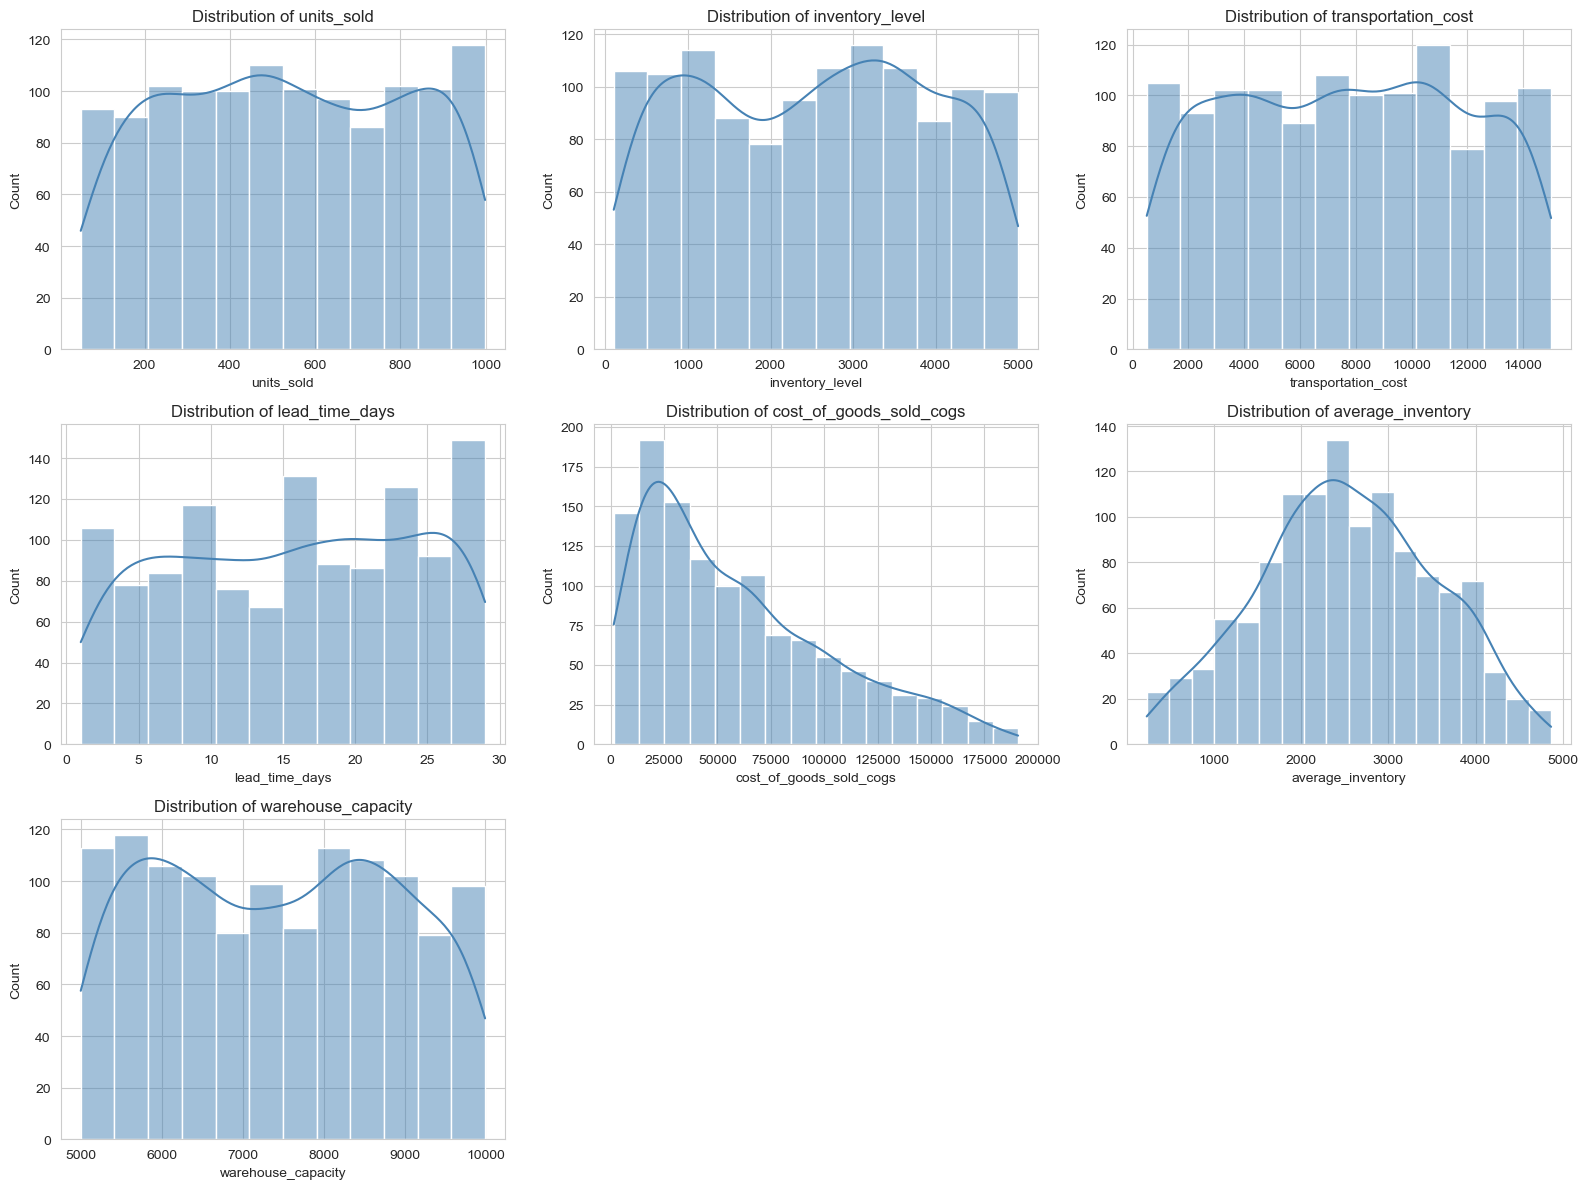

In [18]:
num_features = ["units_sold", "inventory_level", "transportation_cost",
                 "lead_time_days", "cost_of_goods_sold_cogs",
                 "average_inventory", "warehouse_capacity"]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(num_features):
    sns.histplot(df[col], kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"Distribution of {col}")
for j in range(len(num_features), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

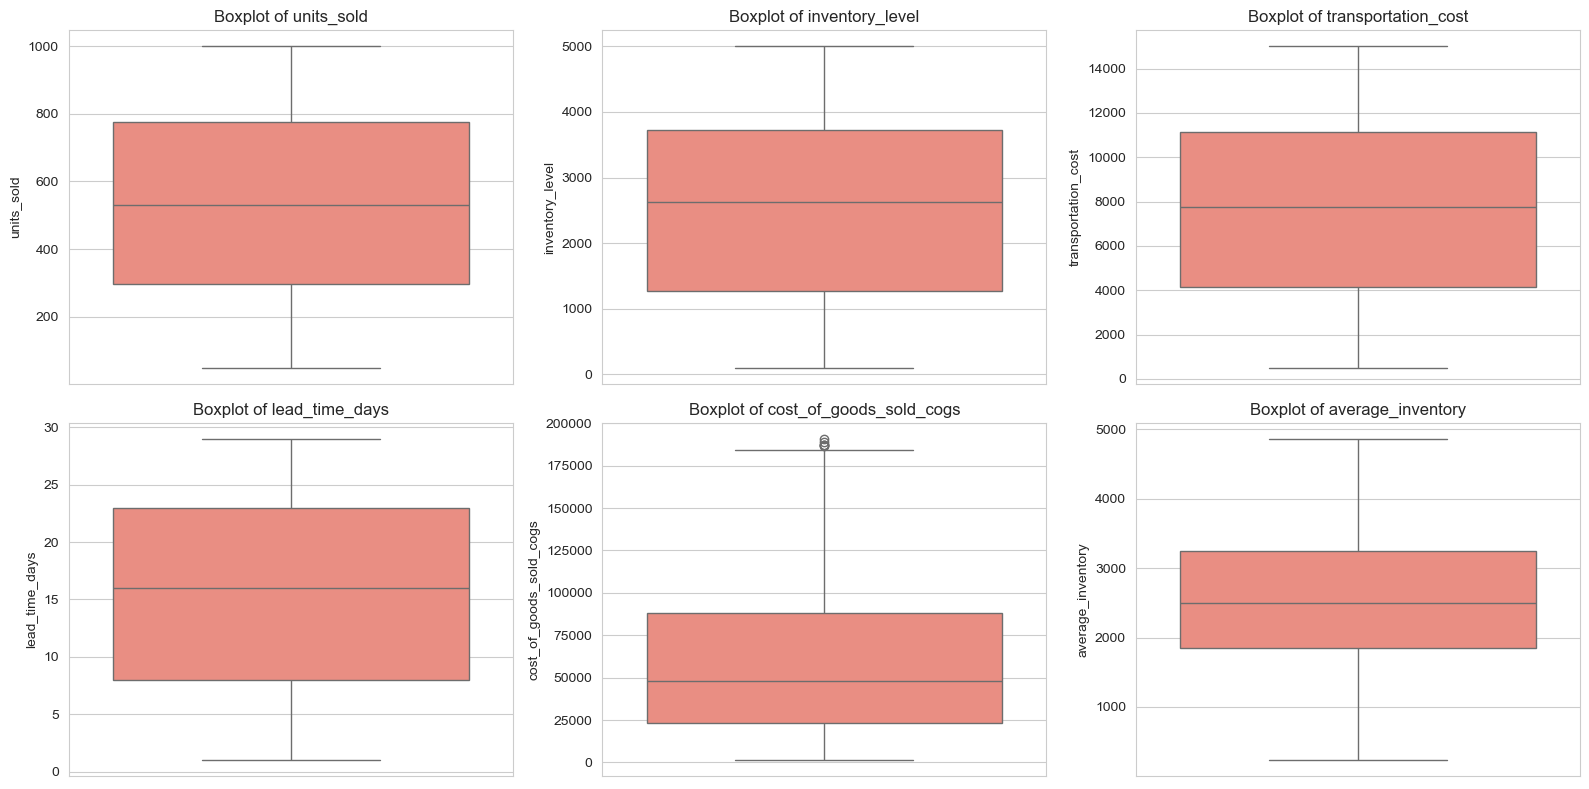

In [19]:
# 17. Boxplots for outlier visualization
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(num_features[:6]):
    sns.boxplot(y=df[col], ax=axes[i], color="salmon")
    axes[i].set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

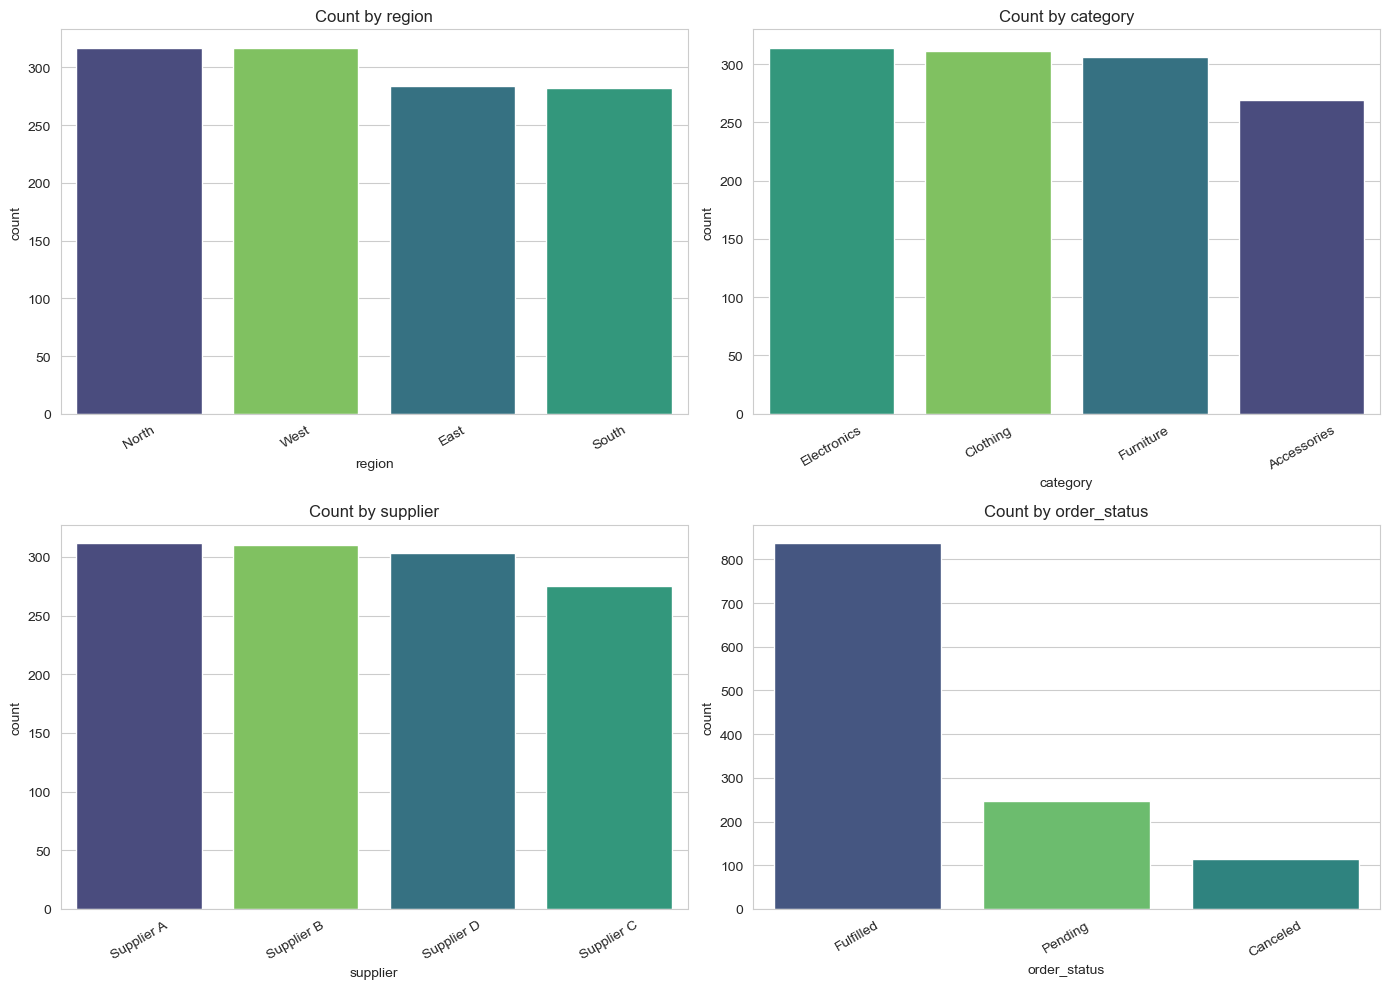

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
cat_plot_cols = ["region", "category", "supplier", "order_status"]
for i, col in enumerate(cat_plot_cols):
    if col in df.columns:
        order = df[col].value_counts().index
        sns.countplot(data=df, x=col, ax=axes[i], order=order, hue=col,
                      palette="viridis", legend=False)
        axes[i].set_title(f"Count by {col}")
        axes[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

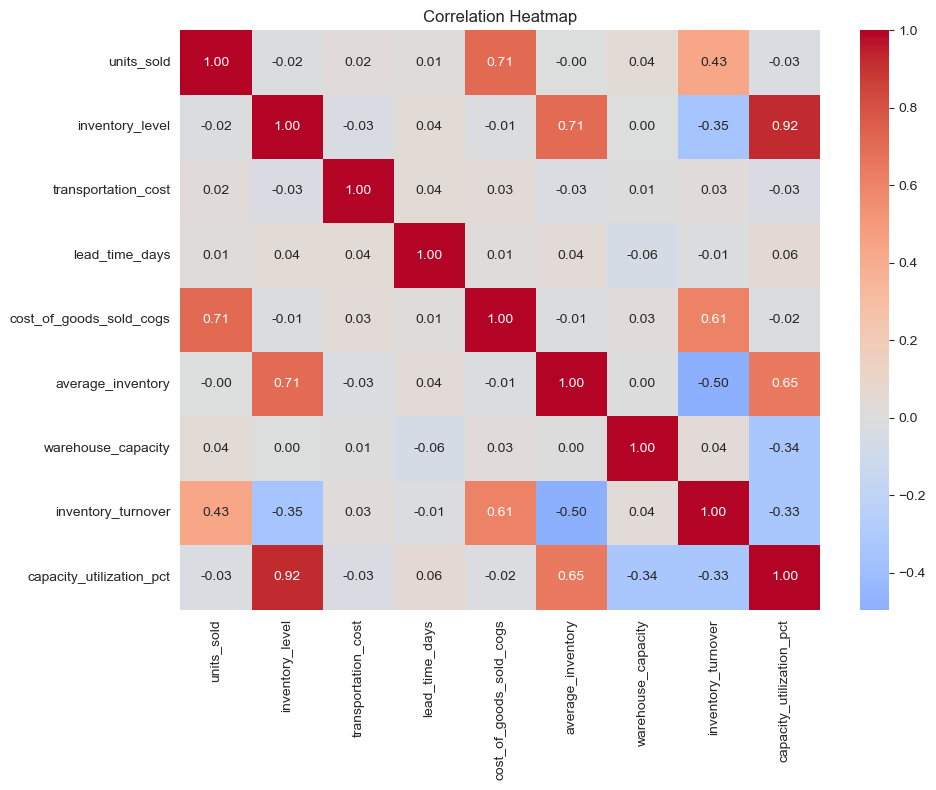

In [21]:
plt.figure(figsize=(10, 8))
corr = df[num_features + ["inventory_turnover", "capacity_utilization_pct"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

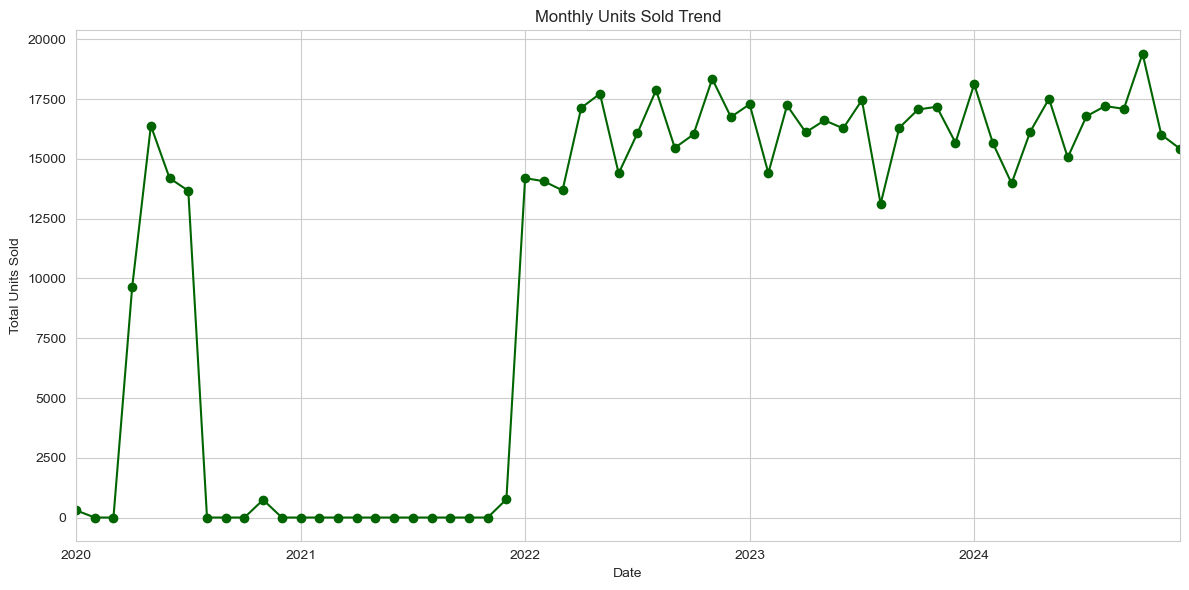

In [23]:
monthly_sales = df.groupby(pd.Grouper(key="date", freq="ME"))["units_sold"].sum()
plt.figure(figsize=(12, 6))
monthly_sales.plot(marker="o", color="darkgreen")
plt.title("Monthly Units Sold Trend")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.show()

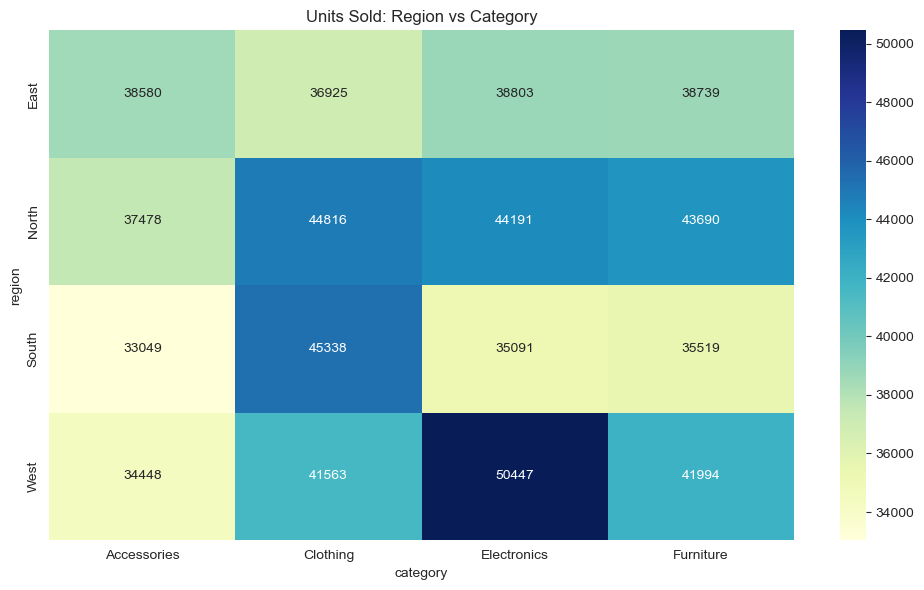

In [24]:
# 21. Region vs Category heatmap (units sold)
pivot = df.pivot_table(values="units_sold", index="region",
                        columns="category", aggfunc="sum", fill_value=0)
plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Units Sold: Region vs Category")
plt.tight_layout()
plt.show()

,backorder_rate,order_accuracy_rate,avg_lead_time,total_units_sold
supplier,,,,
Supplier A,0.070513,0.923077,15.233974,169093
Supplier D,0.122112,0.914191,16.000000,164047
Supplier B,0.103226,0.919355,16.170968,163023
Supplier C,0.090909,0.894545,15.538182,144508


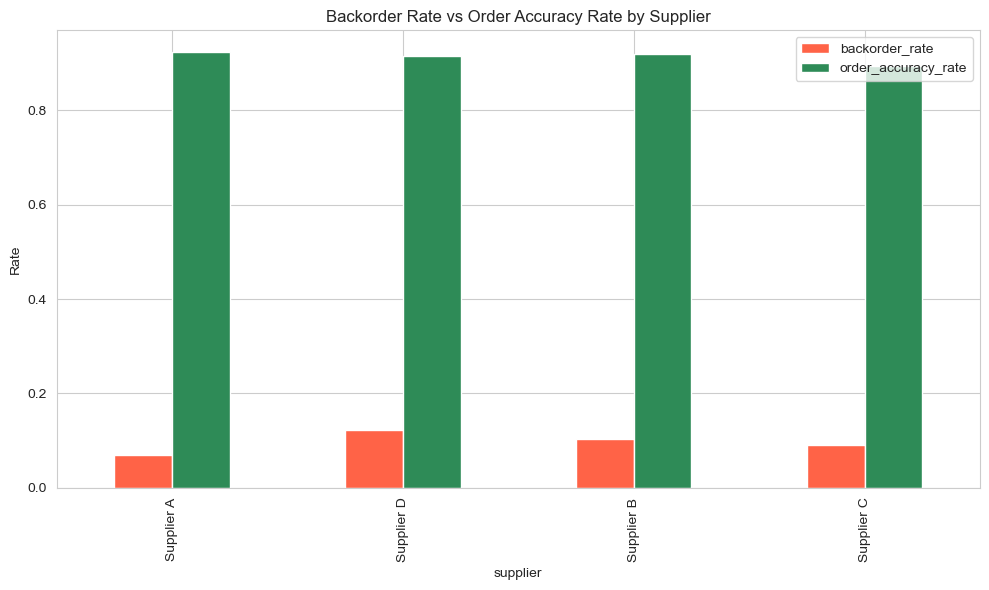

In [25]:
# 22. Supplier performance: backorder rate, order accuracy, lead time
supplier_perf = df.groupby("supplier").agg(
    backorder_rate=("backorder", "mean"),
    order_accuracy_rate=("order_accuracy", "mean"),
    avg_lead_time=("lead_time_days", "mean"),
    total_units_sold=("units_sold", "sum"),
).sort_values("total_units_sold", ascending=False)

display(supplier_perf)

supplier_perf[["backorder_rate", "order_accuracy_rate"]].plot(
    kind="bar", figsize=(10, 6), color=["tomato", "seagreen"]
)
plt.title("Backorder Rate vs Order Accuracy Rate by Supplier")
plt.ylabel("Rate")
plt.tight_layout()
plt.show()

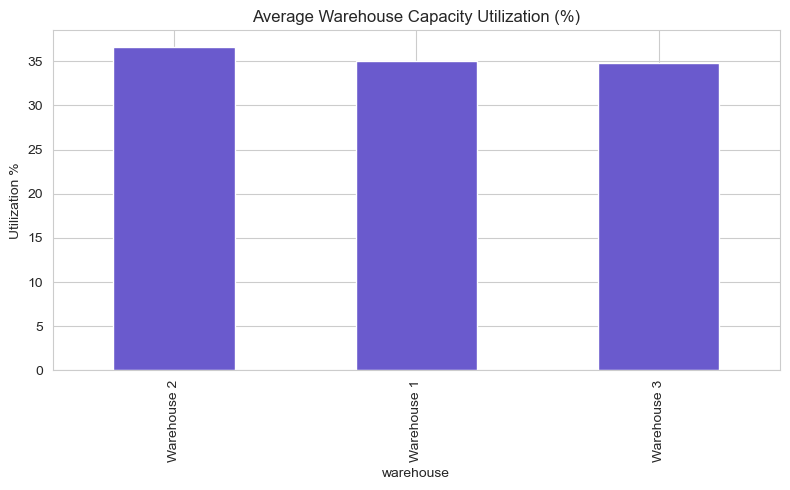

In [26]:
# 23. Warehouse capacity utilization
warehouse_util = df.groupby("warehouse")["capacity_utilization_pct"].mean().sort_values(ascending=False)
warehouse_util.plot(kind="bar", color="slateblue", figsize=(8, 5))
plt.title("Average Warehouse Capacity Utilization (%)")
plt.ylabel("Utilization %")
plt.tight_layout()
plt.show()